# Import Modules

In [ ]:
from dotenv import load_dotenv
load_dotenv()


import pymupdf
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
import easyocr, os

from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

from langchain_openai import ChatOpenAI


import os
from langchain_openai import AzureChatOpenAI


from typing import TypedDict
from langgraph.graph import StateGraph, START, END

from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate

from redisvl.extensions.cache.llm import SemanticCache 
from redisvl.utils.vectorize import HFTextVectorizer
from urllib.parse import quote
import time







# Create the LLM


In [226]:

llm = AzureChatOpenAI(
    azure_deployment="gpt-4.1-mini",   # Azure mein tumne jo deployment name rakha hai
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version="2024-12-01-preview",  # apne resource ke hisaab se check karo
    temperature=0,
)

# Read the PDF with Easy OCR

* Recognition: https://github.com/JaidedAI/EasyOCR/releases/download/v1.3/english_g2.zip
* Detector: https://github.com/JaidedAI/EasyOCR/releases/download/pre-v1.1.6/craft_mlt_25k.zip

In [4]:
data_path = r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\Data\NEJMoa1501352.pdf"
study_name=os.path.basename(data_path)
writing_path =r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\x_smantic_cache\data\my_data.txt"

In [228]:
# Easy OCR + Document
def DocumentExtraction(path):

    reader = easyocr.Reader(['en'], gpu=False)

    docs=[]
    pdf=pymupdf.open(data_path)
    for i, page in enumerate(pdf):
        img = page.get_pixmap(dpi=200).tobytes('png')
        text =" ".join(reader.readtext(img, detail=0))
        docs.append(Document(
            page_content=text, metadata={'page': i+1, 'study_name': study_name}
        ))
    return docs
docs=DocumentExtraction(path=data_path)


Using CPU. Note: This module is much faster with a GPU.
c:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\pharmaEnv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


# Get the Mean of the each page words

In [ ]:

def MeanFinder(docs):
    import pandas as pd

    rows=[ 
        {"Page": i+1, "word_count":len(x.page_content.split())} for i, x in enumerate(docs)
        ]
    df=pd.DataFrame(rows)
    
    return int(df['word_count'].mean()//1)


In [ ]:
# Make the chunker
def Chunker(docs):

    chunker = RecursiveCharacterTextSplitter(chunk_size=3500, chunk_overlap=MeanFinder(docs=docs))
    return chunker.split_documents(docs)

# Make the Vectore Store

In [ ]:


db_path =r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\x_smantic_cache\db\chorma_db"

def embedding(db_path,chunks):
     embeddings = HuggingFaceEmbeddings(
                model_name="sentence-transformers/all-MiniLM-L6-v2"  # local, free
            )
     if os.path.exists(db_path):
        print("Vectore Storage present")
        vectorstore=Chroma(collection_name="pharma_studies", embedding_function=embeddings, persist_directory=db_path)
        return vectorstore
     else:
        print("Creating Vectore Store")

       

        vectorstore = Chroma.from_documents(
            documents=chunks,
            embedding=embeddings,
            collection_name="pharma_studies",
            persist_directory=db_path,  # disk par save hoga
        )

        # test
        results = vectorstore.similarity_search("sitagliptin cardiovascular outcomes", k=3)
        for r in results:
            print(r.metadata, r.page_content[:200], "\n")

        return vectorstore 
vectore_store=embedding(db_path,chunks=Chunker(docs))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Vectore Storage present


# Make the Retriver

In [153]:
def GetRetriver(vectore_store):
    return vectore_store.as_retriever(search_type='mmr', search_kwargs={'k': 5, "fetch_k": 20, "lambda_mult":0.5})
retriver=GetRetriver(vectore_store)

# Cache builder

In [258]:


REDIS_URL= (
f"rediss://:{quote(os.environ['REDIS_KEY'])}"
f"@{os.environ['REDIS_HOST']}:10000"
)

cache=SemanticCache(
name = 'pahrma_cache',
redis_url=REDIS_URL, 
vectorizer=HFTextVectorizer(model="sentence-transformers/all-MiniLM-L6-v2"), 
distance_threshold=0.1,
ttl=3600
)

# counter 
import redis
r=redis.Redis.from_url(REDIS_URL, decode_responses=True)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

# Graph Builder

In [ ]:
class RagState(TypedDict):
    question : str 
    context : str 
    answer : str
    cache_hit: bool 
    

# Grpah Functions

In [265]:
def StringAggrigation(state: RagState):
    retriver=GetRetriver(vectore_store)
    retrived_docs=retriver.invoke(state['question'])
    text=[f"Metadata: {x.metadata} --> Page Content: {x.page_content}" for x in retrived_docs]
    return {"context": "\n\n".join(text)}



def Generation(state: RagState):
    prompt=ChatPromptTemplate.from_messages(
        [
            ("system", """You are a RAG LLM, see the question given by the user and give the answer from the given context only
                    if you dont find the answer in the context just say you don't know no assumtion
              
                CONTEXT:\n{context}
     """),
     
     ('human', "{question}")]
    )

  
        
    messages = prompt.invoke({"question": state['question'], "context": state['context']})
    return {"answer": llm.invoke(messages).content}



def CacheCheck(state: RagState):
    # checking the question if present in the cache
    q=state['question']
    r.zincrby("stats:asked", 1, q)
    hits = cache.check(prompt=state['question'], num_results=1)

    if hits:
        return {'answer': hits[0]['response'], 'cache_hit': True}
    return {'cache_hit': False}

# The cache routher
def route_after_cache(state: RagState):
    return 'hit' if state['cache_hit'] else 'miss'


def CacheStore(state: RagState):
    """If Cache does not contain the question then store the question and answer"""
    cache.store(prompt=state['question'], response=state['answer'])
    return {}





    


# Graph Building

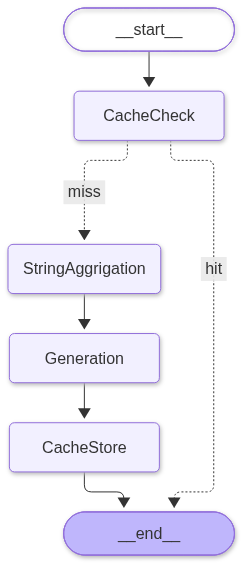

In [260]:

builder = StateGraph(RagState)
nodes = {
    "StringAggrigation": StringAggrigation,
    "Generation": Generation,
    "CacheCheck": CacheCheck,
    "CacheStore": CacheStore
}

for name,fn in nodes.items():
    builder.add_node(name,fn)

builder.add_edge(START, "CacheCheck")

builder.add_conditional_edges(
    "CacheCheck", route_after_cache, 
                    {'hit': END, 'miss':"StringAggrigation"}
)
builder.add_edge("StringAggrigation", "Generation")
builder.add_edge("Generation", "CacheStore")
builder.add_edge("CacheStore", END)
app=builder.compile()

app



# Check the Question if not chache 

In [261]:
input={"question":"What is the cvd outcome of tecos ?"}


start=time.perf_counter()
answer=app.invoke(input)
end=time.perf_counter()
print(f"Cahce Hit:{ answer['cache_hit']}")
print("*"*100)
print(f"Question: {answer['question']}")
print(f"Answer: {answer['answer']}")
print("*"*100)
non_cache = end-start
print(f"Time Taken: {round((end-start),4)} sec")


Cahce Hit:True
****************************************************************************************************
Question: What is the cvd outcome of tecos ?
Answer: The TECOS study found that among patients with type 2 diabetes and established cardiovascular disease, adding sitagliptin to usual care did not increase the risk of major adverse cardiovascular events. The hazard ratio for the primary composite cardiovascular outcome was 0.98 (95% CI, 0.88 to 1.09; P<0.001 for noninferiority), indicating no significant difference compared to placebo. Additionally, there was no significant difference in rates of hospitalization for heart failure (hazard ratio, 1.00; 95% CI, 0.83 to 1.20; P=0.98) or other adverse events such as acute pancreatitis or pancreatic cancer. Overall, sitagliptin did not increase cardiovascular risk in this patient population.
****************************************************************************************************
Time Taken: 3.5849 sec


# Check the Question if chache 

In [262]:
input={"question":"What is the cvd outcome of tecos ?"}


start=time.perf_counter()
answer=app.invoke(input)
end=time.perf_counter()
print(f"Cahce Hit:{ answer['cache_hit']}")
print("*"*100)
print(f"Question: {answer['question']}")
print(f"Answer: {answer['answer']}")
print("*"*100)
with_cache = end-start
print(f"Time Taken: {round((end-start),4)} sec")
print(f"Cache is fater than Non-Cache-->:{(non_cache/with_cache)//1}x")


Cahce Hit:True
****************************************************************************************************
Question: What is the cvd outcome of tecos ?
Answer: The TECOS study found that among patients with type 2 diabetes and established cardiovascular disease, adding sitagliptin to usual care did not increase the risk of major adverse cardiovascular events. The hazard ratio for the primary composite cardiovascular outcome was 0.98 (95% CI, 0.88 to 1.09; P<0.001 for noninferiority), indicating no significant difference compared to placebo. Additionally, there was no significant difference in rates of hospitalization for heart failure (hazard ratio, 1.00; 95% CI, 0.83 to 1.20; P=0.98) or other adverse events such as acute pancreatitis or pancreatic cancer. Overall, sitagliptin did not increase cardiovascular risk in this patient population.
****************************************************************************************************
Time Taken: 0.7225 sec
Cache is fater

# Most Asked Question

In [263]:
def show_stats(n=10):
    print("Most asked (exact text):")
    for q, c in r.zrevrange("stats:asked", 0, n - 1, withscores=True):
        print(f"  {int(c):>4}  {q}")
    print("Most cache hits (by cached question):")
    for q, c in r.zrevrange("stats:hits", 0, n - 1, withscores=True):
        print(f"  {int(c):>4}  {q}")

show_stats()

Most asked (exact text):
     2  What is the cvd outcome of tecos ?
Most cache hits (by cached question):
